# Bioluminescence scan

This notebook runs the active Jupyter kernel environment to scan nightly video folders from the NAS without downloading them. Results are kept in one master CSV; nights already recorded there are skipped unless added to `rerun_nights`.

Use the Run button (or Shift+Enter) to execute each cell.

In [ ]:
import os
import subprocess
from pathlib import Path

# Find the analysis folder from either the repo root or a folder inside it.
cwd = Path.cwd().resolve()
analysis_dir = next(
    (candidate for parent in (cwd, *cwd.parents)
     for candidate in (parent / 'tank-bioluminescence-scan', parent)
     if (candidate / 'scan_bioluminescence.py').is_file()
     and (candidate / 'classify_bioluminescence.py').is_file()),
    None,
)
if analysis_dir is None:
    raise FileNotFoundError(
        'Cannot find the analysis scripts. Open this notebook from the '
        'manta-analysis repository and use a kernel working directory inside it.'
    )
script = analysis_dir / 'scan_bioluminescence.py'
data_root = Path('/Volumes/oakley_lab/aquarium/2026Pan')
output_dir = analysis_dir / 'output'
output_dir.mkdir(parents=True, exist_ok=True)

print('scan script:', script)
print('script exists:', script.is_file())
excluded_nights = {'20261110'}
night_dirs = []  # Clear any nights left over from an earlier run.
try:
    night_dirs = sorted(p for p in data_root.iterdir() if p.is_dir() and p.name.isdigit() and len(p.name) == 8 and p.name not in excluded_nights)
except OSError as exc:
    print(f'Cannot access the NAS video folder: {data_root}')
    print('Connect to the lab NAS: open Finder, press Command + K, '
          'enter smb://oakley-nas1/oakley_lab, and click Connect.')
    print('Then rerun this cell before starting the scan. '
          'If already connected, check the folder path and your access permissions.')
    print(f'Details: {exc.strerror or exc}')
else:
    print('nights found:', [p.name for p in night_dirs])
print('output dir:', output_dir)

In [3]:
import re
import pandas as pd
import shutil
import sys
import tempfile

conda_python = sys.executable
master_csv = output_dir / 'bioluminescence_hits.csv'
analysis_log = output_dir / 'analyzed_nights.txt'
rerun_nights = {''} # example: {'20261117'}

if master_csv.exists():
    master_df = pd.read_csv(master_csv)
    if 'night' not in master_df.columns:
        normalized_video = master_df['video'].str.replace('\\\\', '/', regex=False)
        master_df['night'] = normalized_video.str.extract(r'(?<!\d)(20\d{6})(?!\d)')[0]
else:
    legacy_csvs = sorted(output_dir.glob('*_hits.csv'))
    legacy_frames = [pd.read_csv(path) for path in legacy_csvs]
    master_df = pd.concat(legacy_frames, ignore_index=True) if legacy_frames else pd.DataFrame()
    if not master_df.empty and 'night' not in master_df.columns:
        normalized_video = master_df['video'].str.replace('\\\\', '/', regex=False)
        master_df['night'] = normalized_video.str.extract(r'(?<!\d)(20\d{6})(?!\d)')[0]
    if not master_df.empty:
        master_df.to_csv(master_csv, index=False)

analyzed_nights = set(analysis_log.read_text().splitlines()) if analysis_log.exists() else set()
processed_nights = analyzed_nights | (set(master_df['night'].dropna().astype(str)) if not master_df.empty else set())
for night_dir in night_dirs:
    night = night_dir.name
    if night in processed_nights and night not in rerun_nights:
        print(f'Skipping {night}: already present in {master_csv}')
        continue

    if night in rerun_nights:
        for old_thumb in (output_dir / 'thumbs').glob(f'{night}_*.png'):
            old_thumb.unlink()

    if night in rerun_nights and not master_df.empty:
        master_df = master_df[master_df['night'].astype(str) != night].copy()
        print(f'Removing previous rows for {night} before rerunning')

    staging_dir = Path(tempfile.mkdtemp(prefix=f'bioluminescence_{night}_'))
    cmd = [
        conda_python, str(script), str(night_dir),
        '--output', str(staging_dir),
        '--sample-rate-hz', '2.5',
        '--black', '150',
        '--min-area', '20',
        '--max-area', '1000',
        '--brightness-threshold', '35',
        '--exclude-roi', '0,0,0.15,0.40',
        '--save-thumbs',
        '--thumb-time-gap-sec', '5',
        '--thumb-position-gap-px', '15',
    ]
    print(f'\nScanning night {night}: {night_dir}')
    result = subprocess.run(cmd, text=True)
    if result.returncode != 0:
        print(f'Scan failed for {night}; leaving existing master data unchanged')
        shutil.rmtree(staging_dir, ignore_errors=True)
        continue

    night_csv = staging_dir / 'bioluminescence_hits.csv'
    if not night_csv.exists():
        print(f'No CSV produced for {night}')
        shutil.rmtree(staging_dir, ignore_errors=True)
        continue
    night_df = pd.read_csv(night_csv)
    if not night_df.empty:
        night_df['night'] = night
        master_df = pd.concat([master_df, night_df], ignore_index=True)
    master_df.to_csv(master_csv, index=False)
    analyzed_nights.add(night)
    analysis_log.write_text('\n'.join(sorted(analyzed_nights)) + '\n')

    master_thumb_dir = output_dir / 'thumbs'
    master_thumb_dir.mkdir(parents=True, exist_ok=True)
    for thumb in (staging_dir / 'thumbs').glob('*.png'):
        shutil.copy2(thumb, master_thumb_dir / f'{night}_{thumb.name}')
    for lighting_name in ('lighting_samples.csv', 'lighting_transitions.csv'):
        lighting_file = staging_dir / lighting_name
        if lighting_file.exists():
            shutil.copy2(lighting_file, output_dir / f'{night}_{lighting_name}')
    shutil.rmtree(staging_dir, ignore_errors=True)
    processed_nights.add(night)
    print(f'Added {len(night_df)} detections for {night}')

lighting_transition_files = sorted(output_dir.glob('*_lighting_transitions.csv'))
if lighting_transition_files:
    pd.concat([pd.read_csv(path) for path in lighting_transition_files], ignore_index=True).to_csv(output_dir / 'lighting_transitions.csv', index=False)
print(f'Master CSV: {master_csv}')
print(f'Lighting transitions: {output_dir / "lighting_transitions.csv" if lighting_transition_files else "none"}')

Skipping 20261111: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv
Skipping 20261112: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv
Skipping 20261113: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv
Skipping 20261114: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv
Skipping 20261115: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv
Skipping 20261116: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv
Skipping 20261117: already present in /Users/oakley/temporary/output/bioluminescence_hits.csv

Scanning night 20261118: /Volumes/oakley_lab/aquarium/2026Pan/20261118
Scanning directory: /Volumes/oakley_lab/aquarium/2026Pan/20261118
Scanning: /Volumes/oakley_lab/aquarium/2026Pan/20261118/20261119T015509Z_b779144d_001.mp4
Progress: 205.2s
Progress: 311.2s
Progress: 311.6s
Progress: 312.0s
Progress: 312.4s
Progress: 312.8s
Progress: 31

libpng error: Write Error
libpng error: Write Error
libpng error: Write Error


Progress: 1590.0s
Progress: 1620.0s


libpng error: Write Error


Progress: 1650.0s
Progress: 1680.0s
Progress: 1710.0s
Progress: 1740.0s
Progress: 1770.0s
Progress: 1800.0s
Scanning: /Volumes/oakley_lab/aquarium/2026Pan/20261118/20261119T022505Z_b779144d_001.mp4
Progress: 0.0s
Progress: 30.0s
Progress: 60.0s
Progress: 90.0s
Progress: 120.0s
Progress: 150.0s
Progress: 180.0s
Progress: 210.0s
Progress: 240.0s
Progress: 270.0s
Progress: 300.0s
Progress: 330.0s
Progress: 360.0s
Progress: 390.0s
Progress: 420.0s
Progress: 450.0s
Progress: 480.0s
Progress: 510.0s


libpng error: Write Error


... (21 outputs left out)

libpng error: Write Error


Progress: 270.0s
Progress: 300.0s
Progress: 330.0s
Progress: 360.0s
Progress: 390.0s
Progress: 420.0s
Progress: 450.0s
Progress: 480.0s
Progress: 510.0s
Progress: 540.0s
Progress: 570.0s
Progress: 600.0s
Progress: 630.0s
Progress: 660.0s
Progress: 690.0s
Progress: 720.0s
Progress: 750.0s
Progress: 780.0s
Progress: 810.0s
Progress: 840.0s
Progress: 870.0s
Progress: 900.0s
Progress: 930.0s
Progress: 960.0s
Progress: 990.0s
Progress: 1020.0s
Progress: 1050.0s
Progress: 1080.0s
Progress: 1110.0s
Progress: 1140.0s
Progress: 1170.0s
Progress: 1200.0s
Progress: 1230.0s
Progress: 1260.0s
Progress: 1290.0s
Progress: 1320.0s
Progress: 1350.0s
Progress: 1380.0s
Progress: 1410.0s
Progress: 1440.0s
Progress: 1470.0s
Progress: 1500.0s
Progress: 1530.0s
Progress: 1560.0s
Progress: 1590.0s
Progress: 1620.0s
Progress: 1650.0s
Progress: 1680.0s
Progress: 1710.0s
Progress: 1740.0s
Progress: 1770.0s
Scanning: /Volumes/oakley_lab/aquarium/2026Pan/20261118/20261119T122505Z_b779144d_001.mp4
Progress: 0.0s
Pr

Traceback (most recent call last):
  File "/Users/oakley/temporary/scan_bioluminescence.py", line 816, in <module>
    raise SystemExit(main())
                     ^^^^^^
  File "/Users/oakley/temporary/scan_bioluminescence.py", line 794, in main
    scan_directory(
  File "/Users/oakley/temporary/scan_bioluminescence.py", line 646, in scan_directory
    with csv_path.open("w", newline="") as fh:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/Caskroom/miniforge/base/envs/opencv/lib/python3.11/pathlib.py", line 1044, in open
    return io.open(self, mode, buffering, encoding, errors, newline)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: [Errno 28] No space left on device: '/var/folders/tn/59f7c_s5607_kmwbdt2x885c0000gq/T/bioluminescence_20261118_ok6ntdv1/bioluminescence_hits.csv'


Scan failed for 20261118; leaving existing master data unchanged
Master CSV: /Users/oakley/temporary/output/bioluminescence_hits.csv
Lighting transitions: /Users/oakley/temporary/output/lighting_transitions.csv


In [53]:
import pandas as pd
from pathlib import Path

combined_csv = output_dir / 'bioluminescence_hits.csv'
csv_files = [combined_csv] if combined_csv.exists() else sorted(output_dir.glob('*_hits.csv'))
print('CSV files found:', csv_files)
frames = [pd.read_csv(csv_file) for csv_file in csv_files]
df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print('Total detections:', len(df))
display(df)

CSV files found: [PosixPath('/Users/oakley/temporary/output/bioluminescence_hits.csv')]
Total detections: 5070


,night,video,frame,time_sec,x,y,y_flipped,area,min_intensity,max_intensity,mean_intensity,bbox_x,bbox_y,bbox_width,bbox_height
0,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17262,1150.800,1117,555,525,41.5,151.0,255.0,230.727,1114,551,7,11
1,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17268,1151.200,1109,559,521,80.0,150.0,255.0,230.269,1107,547,6,23
2,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17274,1151.600,1103,555,525,69.0,150.0,255.0,233.871,1101,544,6,22
3,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17280,1152.000,1097,552,528,57.0,152.0,255.0,224.615,1095,542,6,20
4,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17328,1155.200,1155,972,108,44.5,158.0,255.0,224.017,1152,968,8,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5065,20261117,/Volumes/oakley_lab/aquarium/2026Pan/20261117/...,52488,1749.567,698,417,663,34.0,150.0,255.0,229.511,696,413,7,9
5066,20261117,/Volumes/oakley_lab/aquarium/2026Pan/20261117/...,52500,1749.967,697,417,663,32.5,150.0,255.0,216.568,694,414,8,7
5067,20261117,/Volumes/oakley_lab/aquarium/2026Pan/20261117/...,5652,188.396,1267,822,258,28.5,168.0,255.0,231.769,1264,820,8,7
5068,20261117,/Volumes/oakley_lab/aquarium/2026Pan/20261117/...,8316,277.195,1222,849,231,22.5,150.0,255.0,233.781,1220,847,6,7


In [54]:
import re
from datetime import datetime, time, timedelta
from pathlib import Path
import cv2
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

combined_csv = output_dir / 'bioluminescence_hits.csv'
if combined_csv.exists():
    df = pd.read_csv(combined_csv)

if 'df' not in globals() or df.empty:
    print('No detections to plot.')
else:
    def video_key(path):
        name = Path(path).name
        legacy = re.search(r'output_(\d+)\.[^.]+$', name)
        if legacy:
            return (0, int(legacy.group(1)))
        timestamp = re.search(r'(20\d{6}T\d{6}Z)', name)
        return (1, timestamp.group(1)) if timestamp else (2, name)

    def video_start(path):
        match = re.search(r'(20\d{6}T\d{6}Z)', Path(path).name)
        return datetime.strptime(match.group(1), '%Y%m%dT%H%M%SZ') if match else None

    def legacy_number(path):
        match = re.search(r'output_(\d+)\.[^.]+$', Path(str(path)).name)
        return int(match.group(1)) if match else None

    def video_duration(video_path):
        cap = cv2.VideoCapture(str(video_path))
        fps = cap.get(cv2.CAP_PROP_FPS) or 0
        frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        cap.release()
        return frame_count / fps if fps > 0 and frame_count > 0 else 26 * 60

    if 'night' not in df.columns:
        normalized_video = df['video'].str.replace('\\\\', '/', regex=False)
        df['night'] = normalized_video.str.extract(r'(?<!\d)(20\d{6})(?!\d)')[0]
    df['night'] = df['night'].astype(str)
    df = df[df['video'].map(legacy_number).notna()].copy()
    night_data = {}
    night_start_times = {}
    overall_max_sec = 0.0
    for night in sorted(df['night'].dropna().unique()):
        night_dir = data_root / night
        offsets = {}
        starts = {}
        elapsed = 0.0
        for path in sorted((p for p in night_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv', '.mts', '.wmv', '.m4v', '.ts'}), key=video_key):
            key = video_key(path)
            starts[key] = video_start(path)
        valid_starts = [value for value in starts.values() if value is not None]
        night_start = min(valid_starts) if valid_starts else datetime.combine(datetime.today(), time(17, 55))
        night_start_times[night] = night_start
        for path in sorted((p for p in night_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv', '.mts', '.wmv', '.m4v', '.ts'}), key=video_key):
            key = video_key(path)
            offsets[key] = (starts[key] - night_start).total_seconds() if starts[key] else elapsed
            elapsed = max(elapsed, offsets[key] + video_duration(path))
        night_df = df[df['night'] == night].copy()
        night_df['video_number'] = night_df['video'].map(video_key)
        night_df['night_elapsed_sec'] = night_df['time_sec'] + night_df['video_number'].map(offsets).fillna(0)
        night_data[night] = night_df
        overall_max_sec = max(overall_max_sec, elapsed)

    fig, axes = plt.subplots(len(night_data), 1, sharex=True, figsize=(15, max(4, 3.5 * len(night_data))))
    axes = [axes] if len(night_data) == 1 else list(axes)
    for ax, (night, night_df) in zip(axes, sorted(night_data.items())):
        clock_times = night_df['night_elapsed_sec'].map(lambda seconds: night_start_times[night] + timedelta(seconds=float(seconds)))
        ax.scatter(clock_times, night_df['x'], s=8, color='orange', alpha=0.7, label='blob x')
        ax.scatter(clock_times, night_df['y'], s=8, color='blue', alpha=0.7, label='blob y')
        ax.set_title(str(night), loc='left')
        ax.set_ylabel('pixel y')
        ax.grid(True, alpha=0.25)
        ax.legend(loc='upper right')
    axes[-1].set_xlabel('Video timestamp (UTC, from filename)')
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
    fig.suptitle('Detected blob positions by night', y=1.0)
    fig.tight_layout()
    plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/oakley_lab/aquarium/2026Pan/20261111'

In [ ]:
import subprocess
import sys

classified_csv = output_dir / 'bioluminescence_hits_classified.csv'
reference_dir = output_dir / 'sand_references'
simulator_log = output_dir / 'simulator_log.csv'
classifier_script = analysis_dir / 'classify_bioluminescence.py'
subprocess.run([
    sys.executable, str(classifier_script),
    '--input', str(output_dir / 'bioluminescence_hits.csv'),
    '--output', str(classified_csv),
    '--reference-output', str(reference_dir),
    '--simulator-log', str(simulator_log),
], check=True)
df_classified = pd.read_csv(classified_csv)
print('Classified detections:', len(df_classified))
display(df_classified['classification'].value_counts().to_frame('count'))

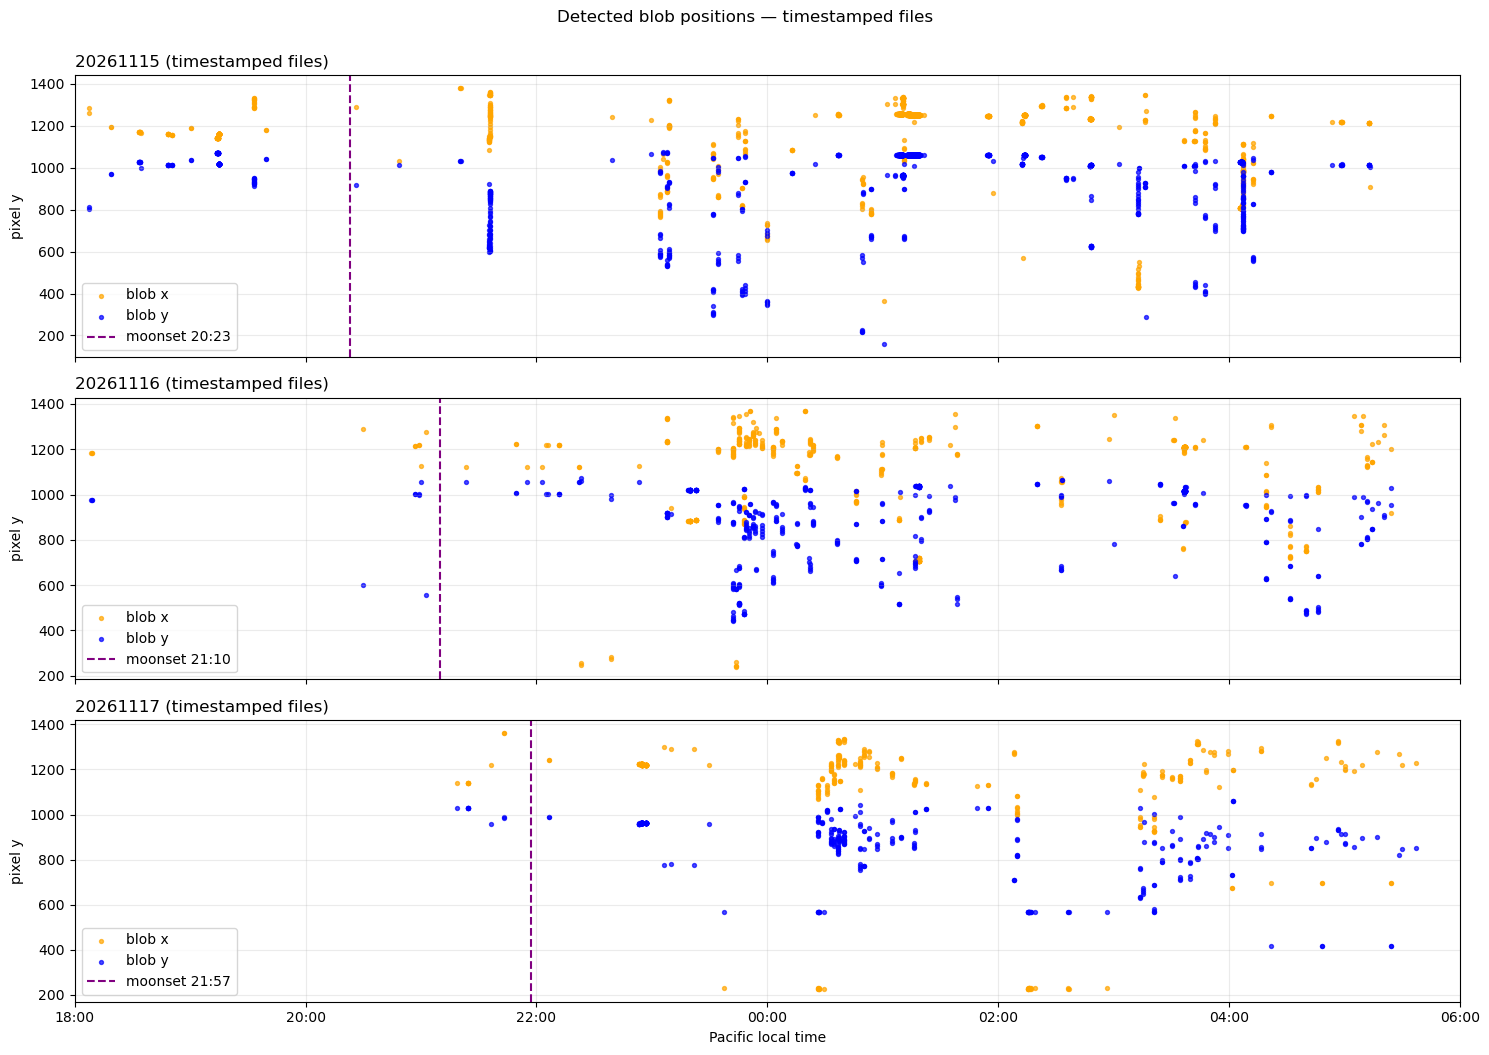

In [49]:
import re
from datetime import datetime, timedelta, timezone
from pathlib import Path
from zoneinfo import ZoneInfo
from astral import moon
from astral import Observer
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

combined_csv = output_dir / 'bioluminescence_hits.csv'
classified_csv = output_dir / 'bioluminescence_hits_classified.csv'
include_reflection_suspects = False
plot_csv = classified_csv if classified_csv.exists() else combined_csv
LOCAL_TZ = ZoneInfo('America/Los_Angeles')
df_timestamp = pd.read_csv(plot_csv)
if not include_reflection_suspects and 'classification' in df_timestamp.columns:
    df_timestamp = df_timestamp[df_timestamp['classification'] != 'reflection_suspect'].copy()

def timestamp_from_video(value):
    match = re.search(r'(20\d{6}T\d{6}Z)', Path(str(value)).name)
    if not match:
        return None
    utc_time = datetime.strptime(match.group(1), '%Y%m%dT%H%M%SZ').replace(tzinfo=timezone.utc)
    return utc_time.astimezone(LOCAL_TZ).replace(tzinfo=None)

BOCAS_OBSERVER = Observer(latitude=9.3402, longitude=-82.2414, elevation=0)

def bocas_night_lunar_events(night):
    night_date = datetime.strptime(night, '%Y%m%d').date()
    window_start = datetime.combine(night_date, datetime.min.time()).replace(hour=18)
    window_end = window_start + timedelta(hours=12)
    events = []
    for event_date in (night_date, night_date + timedelta(days=1)):
        for event_name, event_function in (('moonrise', moon.moonrise), ('moonset', moon.moonset)):
            try:
                event_utc = event_function(BOCAS_OBSERVER, date=event_date, tzinfo=timezone.utc)
            except ValueError:
                continue
            event_local = event_utc.astimezone(LOCAL_TZ).replace(tzinfo=None)
            if window_start <= event_local <= window_end:
                events.append((event_name, event_local))
    return sorted(events, key=lambda item: item[1])

df_timestamp['clock_time'] = df_timestamp['video'].map(timestamp_from_video)
df_timestamp = df_timestamp.dropna(subset=['clock_time']).copy()
if df_timestamp.empty:
    print('No timestamped video detections found.')
else:
    df_timestamp['clock_time'] = df_timestamp['clock_time'] + pd.to_timedelta(df_timestamp['time_sec'], unit='s')
    df_timestamp['night'] = df_timestamp['night'].astype(str)
    nights = sorted(df_timestamp['night'].dropna().unique())
    plot_reference = datetime(2000, 1, 1, 18, 0)
    plot_end = plot_reference + timedelta(hours=12)
    fig, axes = plt.subplots(len(nights), 1, sharex=True, figsize=(15, max(4, 3.5 * len(nights))))
    axes = [axes] if len(nights) == 1 else list(axes)
    for ax, night in zip(axes, nights):
        night_df = df_timestamp[df_timestamp['night'] == night]
        night_start = datetime.strptime(night, '%Y%m%d').replace(hour=18, minute=0, second=0, microsecond=0)
        plot_times = pd.Timestamp(plot_reference) + (pd.to_datetime(night_df['clock_time']) - pd.Timestamp(night_start))
        sand_points = night_df['classification'].eq('reflection_suspect') if 'classification' in night_df.columns else pd.Series(False, index=night_df.index)
        non_sand_points = ~sand_points
        if non_sand_points.any():
            ax.scatter(plot_times.loc[non_sand_points], night_df.loc[non_sand_points, 'x'], s=8, color='orange', alpha=0.7, label='blob x')
            ax.scatter(plot_times.loc[non_sand_points], night_df.loc[non_sand_points, 'y'], s=8, color='blue', alpha=0.7, label='blob y')
        if sand_points.any():
            ax.scatter(plot_times.loc[sand_points], night_df.loc[sand_points, 'x'], s=8, color='firebrick', alpha=0.7, label='sand blob x')
            ax.scatter(plot_times.loc[sand_points], night_df.loc[sand_points, 'y'], s=8, color='lightcoral', alpha=0.7, label='sand blob y')
        for event_name, event_time in bocas_night_lunar_events(night):
            event_plot_time = pd.Timestamp(plot_reference) + (pd.Timestamp(event_time) - pd.Timestamp(night_start))
            ax.axvline(event_plot_time, color='purple', linestyle='--', linewidth=1.5, label=f"{event_name} {event_time.strftime('%H:%M')}")
        ax.set_title(f'{night} (timestamped files)', loc='left')
        ax.set_ylabel('pixel y')
        ax.grid(True, alpha=0.25)
        ax.legend(loc='lower left')
    axes[-1].set_xlabel('Pacific local time')
    axes[-1].set_xlim(plot_reference, plot_end)
    axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    fig.suptitle('Detected blob positions — timestamped files', y=1.0)
    fig.tight_layout()
    plt.show()

Saved /Users/oakley/temporary/output/20261117_moon_vs_sand_reflection.png
Rows plotted: 1748; sand reflections: 1371


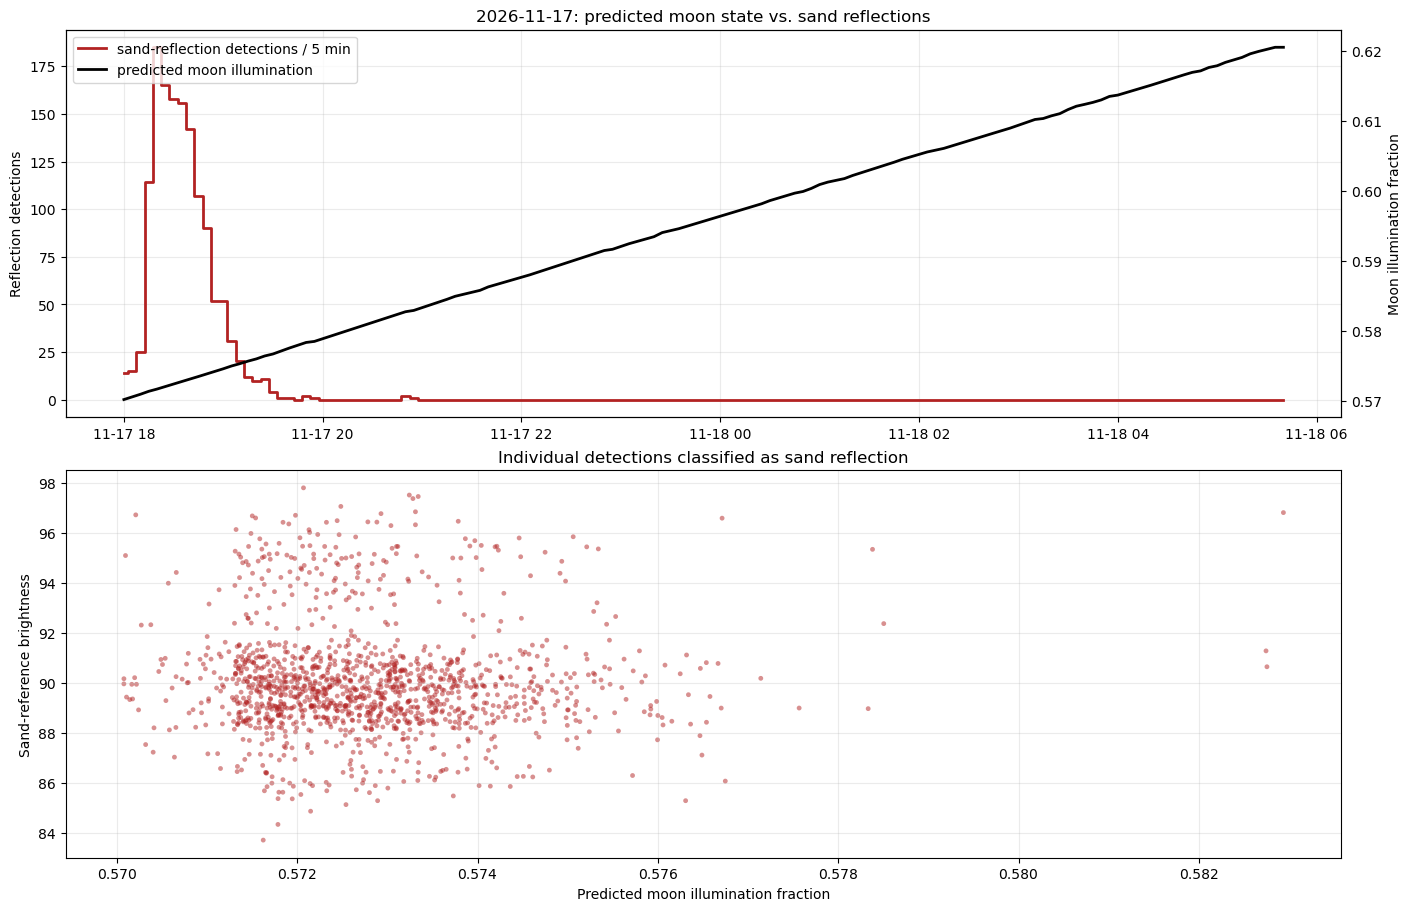

In [50]:
# Last-night moon state versus sand reflection
classified_csv = output_dir / 'bioluminescence_hits_classified.csv'
last_night = '20261117'
plot_df = pd.read_csv(classified_csv)
plot_df = plot_df[plot_df['night'].astype(str) == last_night].copy()
plot_df['time'] = pd.to_datetime(plot_df['inferred_simulator_time'], errors='coerce')
plot_df = plot_df.dropna(subset=['time', 'moon_illumination_fraction'])
reflection = plot_df[plot_df['classification'] == 'reflection_suspect'].copy()
reflection['brightness'] = pd.to_numeric(reflection['reference_brightness'], errors='coerce')
reflection['moon_illumination_fraction'] = pd.to_numeric(reflection['moon_illumination_fraction'], errors='coerce')
reflection = reflection.dropna(subset=['brightness', 'moon_illumination_fraction'])
bins = pd.date_range(plot_df['time'].min().floor('5min'), plot_df['time'].max().ceil('5min'), freq='5min')
counts = reflection.set_index('time').resample('5min').size().reindex(bins, fill_value=0)
illumination = plot_df.set_index('time')['moon_illumination_fraction'].resample('5min').mean().reindex(bins).interpolate()
fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
ax = axes[0]
ax2 = ax.twinx()
ax.step(bins, counts.values, where='mid', color='firebrick', linewidth=2, label='sand-reflection detections / 5 min')
ax2.plot(bins, illumination.values, color='black', linewidth=2, label='predicted moon illumination')
ax.set_ylabel('Reflection detections')
ax2.set_ylabel('Moon illumination fraction')
ax.set_title('2026-11-17: predicted moon state vs. sand reflections')
ax.grid(True, alpha=0.25)
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, loc='upper left')
ax = axes[1]
ax.scatter(reflection['moon_illumination_fraction'], reflection['brightness'], s=12, alpha=0.5, color='firebrick', edgecolors='none')
ax.set_xlabel('Predicted moon illumination fraction')
ax.set_ylabel('Sand-reference brightness')
ax.set_title('Individual detections classified as sand reflection')
ax.grid(True, alpha=0.25)
moon_reflection_plot = output_dir / '20261117_moon_vs_sand_reflection.png'
fig.savefig(moon_reflection_plot, dpi=180)
print(f'Saved {moon_reflection_plot}')
print(f'Rows plotted: {len(plot_df)}; sand reflections: {len(reflection)}')
plt.show()